<a href="https://colab.research.google.com/github/nishapandey9098/medical-image-classifier-calibration/blob/main/Project2_Calibration_Referral.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2: Knowing When Not to Predict
### Calibration, uncertainty and selective referral for medical image classifiers

**Who this is for:** complete beginners. You do **not** need to understand every line of code. Run the cells in order (top to bottom) and read the short explanation above each one.

**The idea.** A medical AI should not only give an answer. It should also say *how sure it is*, and that number should be honest. In Project 1 you trained models that are good on average. Now you ask three questions about them:

1. Are the model's confidence numbers **honest**? (calibration)
2. Can we make them more honest, and get a better "I am not sure" signal? (temperature scaling, ensembles, MC dropout)
3. If the model **refers its least sure cases to a human**, how much more reliable are the cases it still answers? (selective prediction, risk-coverage curves)

**You need:** the results of Project 1 on your Google Drive. This notebook reuses the 5 trained models per dataset (their saved predictions) and trains a few new models with dropout.

**Time:** about 5 minutes for the quick test, about 15 minutes for the full run. Plan about 2 days in total including reading, the README and GitHub.

## Before you start (3 minutes)

1. **Project 1 must be finished.** This notebook reuses its saved predictions. In Google Drive open `ML_Project1_Ablation`, then `full_64px`. You should see `results.csv` and a folder `predictions` with 80 files ending in `.npz`. If not, run the Project 1 notebook with `QUICK_TEST = False` first.
2. Open this notebook in Colab (*File, Upload notebook*). Turn on the free GPU: **Runtime, Change runtime type, T4 GPU, Save.** You need the GPU only for Step 7 (MC dropout).
3. Run each cell with **Shift + Enter**, from top to bottom. Wait for a cell to finish before running the next. Do not skip cells.
4. Start with `QUICK_TEST = True` (about 5 minutes) and switch to `False` for the real run, exactly like in Project 1.
5. If you see red error text, copy the **last 10 lines** and paste them to Claude in your chat.

## Eight ideas you need (read once, 5 minutes)

1. **Confidence.** For every image the model outputs a probability for each class. The biggest one is its *confidence* ("I am 93% sure it is pneumonia").
2. **Calibration.** A model is *calibrated* if its confidence is honest: among all cases where it says "90% sure", it should be right about 90% of the time. A weather forecast works the same way: if it says "70% chance of rain" on 100 days, it should rain on about 70 of them. Neural networks are often **overconfident**: they say 99% and are right 90% of the time.
3. **Reliability diagram.** We sort predictions into confidence bins (for example 0.90 to 0.93) and plot the *real accuracy* in each bin. If the bars follow the diagonal line, the model is calibrated. Bars below the line mean overconfidence.
4. **ECE (expected calibration error).** The average gap between confidence and accuracy over all bins, weighted by how many cases each bin has. 0 is perfect. **NLL** (negative log-likelihood) and the **Brier score** are two more scores that punish confident mistakes. For all three, lower is better.
5. **Temperature scaling (TS).** A one-number fix: divide the model's raw scores (logits) by a number T before turning them into probabilities. T above 1 makes the model less confident. We choose T on the **validation** set. For a single model it never changes which class is predicted, so accuracy stays the same. (For an ensemble or MC dropout, where several predictions are averaged, accuracy can change slightly.)
6. **Ensembles and MC dropout.** Two ways to collect several opinions. An **ensemble** averages the predictions of several separately trained models (you have 5 from Project 1). **MC dropout** keeps dropout switched on at test time and averages many random predictions of one model. If the opinions disagree, the case is uncertain.
7. **Selective prediction ("refer to a clinician").** The model answers only the cases it is most sure about and refers the rest to a human. **Coverage** is the share of cases it answers. **Selective risk** is its error rate on the answered cases. The **risk-coverage curve** plots risk against coverage: a good uncertainty signal makes the curve fall as coverage drops. **AURC** is the area under that curve (lower is better).
8. **Two kinds of uncertainty.** The model's uncertainty about *one case* is what we study. Our uncertainty about the *experiment* (small test sets) is handled with a **bootstrap**: we redraw the test images with replacement many times and see how much a result moves.

**A warning from Project 1:** calibration and ranking are different things. A fix can make the confidence numbers more honest without changing *which* cases look uncertain. You will see an example.

## Step 1: Set up

Cell 1a installs the MedMNIST library. Cell 1b loads the libraries. Cell 1c holds the **settings** (you will change `QUICK_TEST` later, and check `P1_DIR`). Cell 1d connects Google Drive (a pop-up asks for permission: click *Allow*).

In [15]:
# 1a. Install the MedMNIST library. Takes about 30 seconds.
!pip install -q medmnist

In [16]:
# 1b. Load the libraries we need.
import os, time, math, random, itertools, json, platform, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import scipy
import sklearn
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score, cohen_kappa_score
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models

import medmnist
from medmnist import INFO, PneumoniaMNIST, RetinaMNIST

print("Libraries loaded. PyTorch", torch.__version__)

Libraries loaded. PyTorch 2.14.1+cu130


In [17]:
# 1c. SETTINGS (you can change these)
QUICK_TEST = False        # True  = quick check (about 5 minutes).
                         # False = the REAL run (about 15 minutes). Switch only after the quick test works.
P1_DIR = "/content/drive/MyDrive/ML_Project1_Ablation/full_64px"   # the folder where Project 1 saved its results
IMG_SIZE = 64            # must be the same as in Project 1
N_SEEDS = 5              # Project 1 trained 5 models (seeds 0 to 4) for every setting
RUN_MC_DROPOUT = True    # set to False if you have no GPU: you skip MC dropout and still get everything else

DROPOUT_P = 0.3          # chance that a feature is switched off in the dropout models
MC_PASSES = 30           # random predictions that MC dropout averages for every image
N_BINS = 15              # number of confidence bins (ECE and reliability diagrams)
N_BOOT = 1000            # bootstrap repetitions (confidence intervals over the test images)

# Training settings for the new dropout models: the same as in Project 1
EPOCHS = {"pneumoniamnist": 15, "retinamnist": 30}
BATCH_SIZE = 64
LR = 3e-4
WEIGHT_DECAY = 1e-4

if QUICK_TEST:
    N_SEEDS_MC, MC_EPOCHS, MC_PASSES, N_BOOT = 2, {"pneumoniamnist": 2, "retinamnist": 2}, 10, 200
else:
    N_SEEDS_MC, MC_EPOCHS = N_SEEDS, EPOCHS

RUN_NAME = "quick_test" if QUICK_TEST else "full"
USE_GPU = torch.cuda.is_available()
device = torch.device("cuda" if USE_GPU else "cpu")
print("Mode:", "QUICK TEST" if QUICK_TEST else "FULL RUN", "| device:", device, "|",
      str(torch.cuda.get_device_name(0)) if USE_GPU else "NO GPU FOUND")
if RUN_MC_DROPOUT and not USE_GPU and not QUICK_TEST:
    RUN_MC_DROPOUT = False
    print("No GPU found, so MC dropout is switched OFF for this run (on a CPU it would take hours).\n"
          "To include it: Runtime > Change runtime type > T4 GPU, then Runtime > Run all.")

Mode: FULL RUN | device: cuda | Tesla T4


In [18]:
# 1d. Where to save results (Google Drive, so nothing is lost if Colab disconnects).
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/ML_Project2_Calibration"
except Exception as e:
    print("Google Drive not used (" + type(e).__name__ + "). Saving in a local folder instead.")
    BASE_DIR = "./ML_Project2_Calibration"

OUT_DIR = os.path.join(BASE_DIR, RUN_NAME)
for sub in ["", "figures", "mc_logits"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
print("Results will be saved in:", OUT_DIR)

env = {
    "python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__, "opencv": cv2.__version__, "medmnist": getattr(medmnist, "__version__", "unknown"),
    "gpu": str(torch.cuda.get_device_name(0)) if USE_GPU else "none",
    "img_size": IMG_SIZE, "n_seeds_standard": N_SEEDS, "n_seeds_mc_dropout": N_SEEDS_MC, "dropout_p": DROPOUT_P,
    "mc_passes": MC_PASSES, "n_bins": N_BINS, "n_boot": N_BOOT, "mc_epochs": MC_EPOCHS, "batch_size": BATCH_SIZE,
    "learning_rate": LR, "weight_decay": WEIGHT_DECAY, "project1_folder": P1_DIR,
}
with open(os.path.join(OUT_DIR, "environment.json"), "w") as f:
    json.dump(env, f, indent=2)
print(json.dumps(env, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results will be saved in: /content/drive/MyDrive/ML_Project2_Calibration/full
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "scipy": "1.16.3",
  "opencv": "4.14.0",
  "medmnist": "3.0.2",
  "gpu": "Tesla T4",
  "img_size": 64,
  "n_seeds_standard": 5,
  "n_seeds_mc_dropout": 5,
  "dropout_p": 0.3,
  "mc_passes": 30,
  "n_bins": 15,
  "n_boot": 1000,
  "mc_epochs": {
    "pneumoniamnist": 15,
    "retinamnist": 30
  },
  "batch_size": 64,
  "learning_rate": 0.0003,
  "weight_decay": 0.0001,
  "project1_folder": "/content/drive/MyDrive/ML_Project1_Ablation/full_64px"
}


## Step 2: Load what Project 1 saved

This cell reads three things:

- Project 1's `results.csv`, to find the **reference setting** of each dataset: the setting with the best average *validation* score (the same rule Project 1 used; it never looks at the test set).
- The **validation and test labels** (downloaded again from MedMNIST, in the same order as in Project 1).
- The **saved predictions** (raw scores, called *logits*) of the 5 models (seeds 0 to 4) that Project 1 trained with that reference setting.

**What you should see:** the reference setting of each dataset and, for each of the 5 models, the test accuracy computed from the saved predictions next to the accuracy Project 1 wrote in `results.csv`. They should agree (seed 0 may differ a little, because Project 1's Step 9 re-trained it). If they differ a lot, the labels and predictions do not line up, so check that `IMG_SIZE` is the same as in Project 1.

In [19]:
DATASETS = {"pneumoniamnist": PneumoniaMNIST, "retinamnist": RetinaMNIST}
N_CLASSES = {flag: len(INFO[flag]["label"]) for flag in DATASETS}
PRIMARY = {"pneumoniamnist": "auc", "retinamnist": "qwk"}            # Project 1's main score for each dataset
PRIMARY_NAME = {"pneumoniamnist": "AUC", "retinamnist": "QWK"}
NICE = {"pneumoniamnist": "PneumoniaMNIST", "retinamnist": "RetinaMNIST"}

if not os.path.isdir(P1_DIR):
    parent = os.path.dirname(P1_DIR)
    raise FileNotFoundError(
        f"I cannot find your Project 1 folder: {P1_DIR}\n"
        f"Folders found next to it: {os.listdir(parent) if os.path.isdir(parent) else '(its parent folder is missing too)'}\n"
        "Fix P1_DIR in cell 1c so that it points to the folder that contains results.csv and the predictions folder.")

res = pd.read_csv(os.path.join(P1_DIR, "results.csv"))
print(f"Project 1 results loaded: {len(res)} runs, seeds {sorted(res.seed.unique().tolist())}")

def parse_config(name):
    parts = name.split("+")
    return {"pretrained": parts[0] == "pretrained", "augment": "aug" in parts, "clahe": "clahe" in parts}

# labels of the validation and test sets (same order as in Project 1)
labels = {}
for flag in DATASETS:
    labels[flag] = {}
    for split in ["val", "test"]:
        ds = DATASETS[flag](split=split, download=True, size=IMG_SIZE)
        labels[flag][split] = ds.labels.reshape(-1).astype(int)

# reference setting = best mean VALIDATION score in Project 1
REF = {}
for flag in DATASETS:
    d = res[res.dataset == flag]
    best = d.groupby("config")["val_" + PRIMARY[flag]].mean().idxmax()
    REF[flag] = {"config": best, **parse_config(best)}

# saved predictions of the 5 standard models
STD = {}
for flag in DATASETS:
    cfg = REF[flag]["config"]
    STD[flag] = {"val": [], "test": []}
    for s in range(N_SEEDS):
        path = os.path.join(P1_DIR, "predictions", f"{flag}__{cfg}__seed{s}.npz")
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing Project 1 file: {path}\nRun Project 1 (Step 7) first, or check P1_DIR in cell 1c.")
        z = np.load(path)
        zv, zt = z["val_logits"].astype(np.float64), z["test_logits"].astype(np.float64)
        if zv.shape != (len(labels[flag]["val"]), N_CLASSES[flag]) or zt.shape != (len(labels[flag]["test"]), N_CLASSES[flag]):
            raise ValueError(f"The shape of {path} does not match the labels. Is IMG_SIZE the same as in Project 1?")
        STD[flag]["val"].append(zv)
        STD[flag]["test"].append(zt)

for flag in DATASETS:
    cfg = REF[flag]["config"]
    d = res[(res.dataset == flag) & (res.config == cfg)].sort_values("seed")
    acc_here = np.array([(z.argmax(1) == labels[flag]["test"]).mean() for z in STD[flag]["test"]])
    acc_p1 = d["test_accuracy"].values[:N_SEEDS]
    print(f"\n{NICE[flag]}: reference setting = {cfg}")
    print("  test accuracy from the saved predictions:", np.round(acc_here, 3).tolist())
    print("  test accuracy written in results.csv    :", np.round(acc_p1, 3).tolist())
    print("  images: validation", len(labels[flag]["val"]), "| test", len(labels[flag]["test"]))
    if np.abs(acc_here - acc_p1).max() > 0.03:
        print("  WARNING: these differ by more than 0.03. Check IMG_SIZE and P1_DIR (see the text above this cell).")

Project 1 results loaded: 80 runs, seeds [0, 1, 2, 3, 4]

PneumoniaMNIST: reference setting = pretrained+aug
  test accuracy from the saved predictions: [0.913, 0.905, 0.929, 0.897, 0.921]
  test accuracy written in results.csv    : [0.913, 0.905, 0.929, 0.897, 0.921]
  images: validation 524 | test 624

RetinaMNIST: reference setting = pretrained+aug+clahe
  test accuracy from the saved predictions: [0.558, 0.54, 0.548, 0.57, 0.55]
  test accuracy written in results.csv    : [0.558, 0.54, 0.548, 0.57, 0.55]
  images: validation 120 | test 400


## Step 3: The toolbox (and a self-test)

This cell defines all the small functions used in the rest of the notebook. They only need NumPy (no GPU). You do **not** have to read them, but here is what they do:

- `ensemble_proba`: turns raw scores into probabilities. Given *M* sets of scores it averages the *M* predictions. M = 1 is a normal model, M = 5 is an ensemble, M = 30 random dropout passes is MC dropout. One function for all three.
- `ece_score`, `nll_score`, `brier_score`: the three calibration scores.
- `fit_temperature`: finds the best temperature T on the validation set.
- `selective_curve` and `aurc_score`: sort cases from most to least confident and compute the error rate on the answered cases (the risk-coverage curve).
- `confidence_scores`: three ways to measure "how sure" a prediction is: highest probability, (negative) entropy, and (for several opinions) (negative) mutual information, which measures how much the opinions disagree.

The **self-test** at the bottom checks the functions on fake data where we know the right answer. **All lines must print OK.**

In [20]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

def ensemble_proba(logits, T=1.0):
    """logits: array (M, N, C) = M sets of raw scores for N images and C classes.
    Returns the average of softmax(logits / T) over the M sets: an (N, C) array of probabilities."""
    return softmax(np.asarray(logits, dtype=np.float64) / T, axis=-1).mean(axis=0)

def nll_score(proba, y):
    return float(-np.log(np.clip(proba[np.arange(len(y)), y], 1e-12, 1.0)).mean())

def brier_score(proba, y):
    onehot = np.zeros_like(proba)
    onehot[np.arange(len(y)), y] = 1.0
    return float(((proba - onehot) ** 2).sum(axis=1).mean())

def reliability_data(proba, y, n_bins=None):
    """Per confidence bin: mean confidence, accuracy and number of cases (NaN where the bin is empty)."""
    n_bins = n_bins or N_BINS
    conf = proba.max(axis=1)
    correct = (proba.argmax(axis=1) == y).astype(float)
    idx = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    cnt = np.bincount(idx, minlength=n_bins).astype(float)
    s_conf = np.bincount(idx, weights=conf, minlength=n_bins)
    s_acc = np.bincount(idx, weights=correct, minlength=n_bins)
    with np.errstate(invalid="ignore", divide="ignore"):
        return s_conf / cnt, s_acc / cnt, cnt

def ece_score(proba, y, n_bins=None):
    n_bins = n_bins or N_BINS
    conf = proba.max(axis=1)
    correct = (proba.argmax(axis=1) == y).astype(float)
    idx = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    s_conf = np.bincount(idx, weights=conf, minlength=n_bins)
    s_acc = np.bincount(idx, weights=correct, minlength=n_bins)
    return float(np.abs(s_acc - s_conf).sum() / len(y))      # = sum over bins of (share of cases) x |accuracy - confidence|

def fit_temperature(logits_val, y_val):
    """Best temperature T (the one with the lowest NLL on the validation set). logits_val: (M, N, C)."""
    loss = lambda T: nll_score(ensemble_proba(logits_val, T), y_val)
    grid = np.exp(np.linspace(np.log(0.1), np.log(10.0), 120))
    losses = [loss(T) for T in grid]
    i = int(np.argmin(losses))
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]
    return float(minimize_scalar(loss, bounds=(lo, hi), method="bounded").x)

def selective_curve(conf, correct, tie_noise):
    """Sort the cases from most to least confident. Returns coverage (share of cases answered) and
    selective risk (error rate among the answered cases). Ties are broken with the random numbers in tie_noise."""
    order = np.lexsort((tie_noise, -conf))
    err = 1.0 - correct[order]
    k = np.arange(1, len(conf) + 1)
    return k / len(conf), np.cumsum(err) / k

def aurc_score(conf, correct, tie_noise):
    """Area under the risk-coverage curve (average selective risk over all coverage levels). Lower is better."""
    return float(selective_curve(conf, correct, tie_noise)[1].mean())

def accuracy_at(conf, correct, tie_noise, coverage):
    order = np.lexsort((tie_noise, -conf))
    k = max(1, int(round(coverage * len(conf))))
    return float(correct[order[:k]].mean())

def qwk_at(conf, pred, y, tie_noise, coverage):
    order = np.lexsort((tie_noise, -conf))
    k = max(1, int(round(coverage * len(conf))))
    keep = order[:k]
    try:
        return float(cohen_kappa_score(y[keep], pred[keep], weights="quadratic"))
    except Exception:
        return float("nan")

def confidence_scores(logits, T=1.0):
    """Different ways to say 'how sure is the model'. Larger = more confident. logits: (M, N, C)."""
    pm = ensemble_proba(logits, T)
    entropy = -(pm * np.log(np.clip(pm, 1e-12, 1.0))).sum(axis=1)
    out = {"highest probability": pm.max(axis=1), "(negative) entropy": -entropy}
    if logits.shape[0] > 1:
        ps = softmax(np.asarray(logits, dtype=np.float64) / T, axis=-1)
        expected_entropy = -(ps * np.log(np.clip(ps, 1e-12, 1.0))).sum(axis=-1).mean(axis=0)
        out["(negative) mutual information"] = -(entropy - expected_entropy)    # larger disagreement = less confident
    return out

NOISE = {flag: np.random.default_rng(2024).random(len(labels[flag]["test"])) for flag in DATASETS}   # for breaking ties

# ---------------------------------------------------------------- self-test on fake data
rng = np.random.default_rng(0)
n = 20000
p1 = rng.uniform(0.5, 1.0, n)                           # confidence of the predicted class (class 0)
correct = rng.random(n) < p1                            # right with exactly that probability = perfectly calibrated
y_fake = np.where(correct, 0, 1)
proba_ok = np.stack([p1, 1 - p1], axis=1)
over = np.clip(p1 + 0.10, 0, 0.999)                     # the same predictions, but 10 points more confident
proba_over = np.stack([over, 1 - over], axis=1)
e_ok, e_over = ece_score(proba_ok, y_fake), ece_score(proba_over, y_fake)
assert e_ok < 0.02 and 0.07 < e_over < 0.13, (e_ok, e_over)
print(f"OK  ECE of perfectly calibrated fake predictions = {e_ok:.3f} (about 0); of overconfident ones = {e_over:.3f} (about 0.10)")

z_cal = np.log(proba_ok[:, :1] / proba_ok[:, 1:])       # raw score difference that is exactly calibrated
logits_fake = np.concatenate([z_cal, np.zeros_like(z_cal)], axis=1)[None] * 3.0   # multiply by 3: now overconfident
T_hat = fit_temperature(logits_fake, y_fake)
assert abs(T_hat - 3.0) < 0.35, T_hat
print(f"OK  temperature scaling recovers the secret factor 3: found T = {T_hat:.2f}")

noise = rng.random(n)
a_model = aurc_score(proba_ok.max(1), correct.astype(float), noise)
a_oracle = aurc_score(correct.astype(float), correct.astype(float), noise)
a_random = aurc_score(rng.random(n), correct.astype(float), noise)
assert a_oracle < a_model < a_random + 1e-9, (a_oracle, a_model, a_random)
print(f"OK  AURC: perfect ranking {a_oracle:.3f} < our confidence {a_model:.3f} < random ranking {a_random:.3f}")

cov_, risk_ = selective_curve(proba_ok.max(1), correct.astype(float), noise)
assert abs(risk_[-1] - (1 - correct.mean())) < 1e-12 and cov_[-1] == 1.0
print("OK  at coverage 100% the risk is the normal error rate")
print("\nAll self-tests passed.")

OK  ECE of perfectly calibrated fake predictions = 0.005 (about 0); of overconfident ones = 0.087 (about 0.10)
OK  temperature scaling recovers the secret factor 3: found T = 2.91
OK  AURC: perfect ranking 0.033 < our confidence 0.120 < random ranking 0.242
OK  at coverage 100% the risk is the normal error rate

All self-tests passed.


## Step 4: Is the raw model overconfident?

We look at one of the Project 1 models (seed 0) and at the average of all 5.

**Confidence histogram (left):** how confident the model is when it is right (blue) and when it is wrong (red). A useful model is *less* confident when it is wrong. If the red bars also sit at 0.95 to 1.0, the model is often confidently wrong.

**Reliability diagrams (middle: validation set, right: test set):** each bar is a confidence bin; its height is the real accuracy in that bin; the dashed diagonal is perfect honesty. The red hatched area is the gap between accuracy and confidence: it sits **above** the bar when the model is overconfident and **inside** the bar when it is underconfident. Pale bars have fewer than 10 cases: do not trust them.

**Two things to keep in mind.** (1) Project 1 kept the epoch with the lowest *validation* loss, which already pushes the model towards good validation calibration, so do not be surprised if the validation diagram looks better than the test diagram. (2) The test sets are small, so the bars move around a lot. We will measure that noise properly in Step 9.

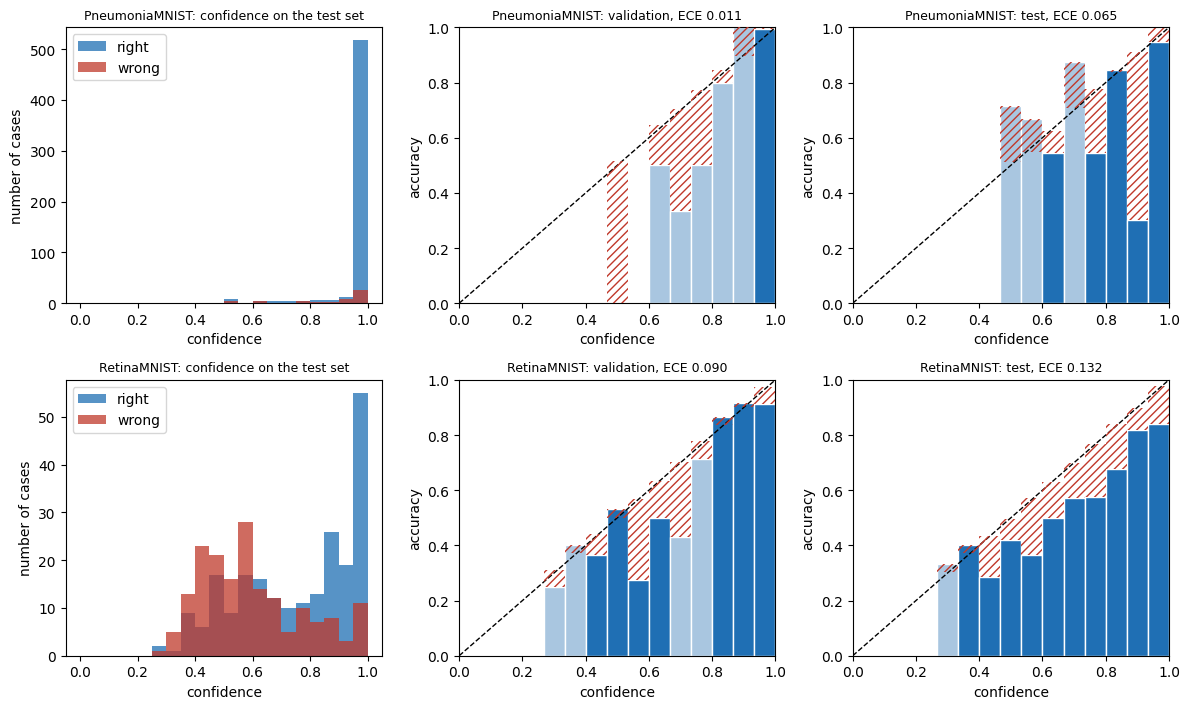

Mean confidence vs accuracy on the TEST set for the 5 Project 1 models (positive gap = overconfident):
  PneumoniaMNIST  seed 0: confidence 0.967 | accuracy 0.913 | gap +0.054
  PneumoniaMNIST  seed 1: confidence 0.951 | accuracy 0.905 | gap +0.045
  PneumoniaMNIST  seed 2: confidence 0.970 | accuracy 0.929 | gap +0.040
  PneumoniaMNIST  seed 3: confidence 0.969 | accuracy 0.897 | gap +0.071
  PneumoniaMNIST  seed 4: confidence 0.975 | accuracy 0.921 | gap +0.054
  RetinaMNIST     seed 0: confidence 0.685 | accuracy 0.557 | gap +0.128
  RetinaMNIST     seed 1: confidence 0.638 | accuracy 0.540 | gap +0.098
  RetinaMNIST     seed 2: confidence 0.714 | accuracy 0.547 | gap +0.167
  RetinaMNIST     seed 3: confidence 0.715 | accuracy 0.570 | gap +0.145
  RetinaMNIST     seed 4: confidence 0.662 | accuracy 0.550 | gap +0.112


In [21]:
def plot_reliability(ax, proba, y, title):
    mean_conf, acc, cnt = reliability_data(proba, y)
    centers = (np.arange(N_BINS) + 0.5) / N_BINS
    ok = cnt > 0
    colors = ["#1f6fb4" if c >= 10 else "#a9c6e0" for c in cnt[ok]]
    ax.bar(centers[ok], acc[ok], width=1.0 / N_BINS, color=colors, edgecolor="white", zorder=2)
    ax.bar(centers[ok], mean_conf[ok] - acc[ok], bottom=acc[ok], width=1.0 / N_BINS, fill=False, hatch="////",
           edgecolor="#c0392b", linewidth=0, zorder=3)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for r_, flag in enumerate(DATASETS):
    yv, yt = labels[flag]["val"], labels[flag]["test"]
    pv, pt = ensemble_proba(STD[flag]["val"][0][None]), ensemble_proba(STD[flag]["test"][0][None])
    conf, ok_ = pt.max(1), pt.argmax(1) == yt
    ax = axes[r_][0]
    ax.hist(conf[ok_], bins=np.linspace(0, 1, 21), color="#1f6fb4", alpha=0.75, label="right")
    ax.hist(conf[~ok_], bins=np.linspace(0, 1, 21), color="#c0392b", alpha=0.75, label="wrong")
    ax.set_title(f"{NICE[flag]}: confidence on the test set", fontsize=9); ax.set_xlabel("confidence"); ax.set_ylabel("number of cases"); ax.legend()
    plot_reliability(axes[r_][1], pv, yv, f"{NICE[flag]}: validation, ECE {ece_score(pv, yv):.3f}")
    plot_reliability(axes[r_][2], pt, yt, f"{NICE[flag]}: test, ECE {ece_score(pt, yt):.3f}")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "figures", "step4_raw_model.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Mean confidence vs accuracy on the TEST set for the 5 Project 1 models (positive gap = overconfident):")
for flag in DATASETS:
    yt = labels[flag]["test"]
    for s in range(N_SEEDS):
        p = ensemble_proba(STD[flag]["test"][s][None])
        print(f"  {NICE[flag]:15s} seed {s}: confidence {p.max(1).mean():.3f} | accuracy {(p.argmax(1) == yt).mean():.3f} | gap {p.max(1).mean() - (p.argmax(1) == yt).mean():+.3f}")

## Step 5: Temperature scaling

For every model we find the temperature T on the **validation** set and then apply it to the **test** set. We never fit anything on the test set.

**How to read the table**
- `T` above 1 means "the model was overconfident on validation, soften it". T below 1 means "the model was *under*confident on validation, sharpen it".
- The *validation* columns improve almost by definition (T was fitted there). **Only the test columns tell you whether it really helps.**
- `acc_test` must not change (temperature scaling never changes the predicted class).

**Be ready for any outcome.** Temperature scaling usually helps, but it only works if the validation set looks like the test set. In Project 1 the models scored much higher on the PneumoniaMNIST validation images than on its test images (accuracy about 0.98 against about 0.89). In that case T may come out too small, and scaling can even make the test calibration *worse*. If you see this, it is a real finding: write it down, do not hide it.

,dataset,seed,T,ECE_val_raw,ECE_val_TS,ECE_test_raw,ECE_test_TS,NLL_test_raw,NLL_test_TS,acc_test_raw,acc_test_TS
0,PneumoniaMNIST,0,1.327,0.011,0.009,0.065,0.056,0.334,0.273,0.913,0.913
1,PneumoniaMNIST,1,0.929,0.014,0.010,0.050,0.052,0.328,0.345,0.905,0.905
2,PneumoniaMNIST,2,1.202,0.005,0.006,0.047,0.039,0.228,0.204,0.929,0.929
3,PneumoniaMNIST,3,1.257,0.013,0.016,0.073,0.064,0.405,0.339,0.897,0.897
4,PneumoniaMNIST,4,1.269,0.012,0.011,0.057,0.047,0.275,0.234,0.921,0.921
5,RetinaMNIST,0,1.341,0.090,0.097,0.132,0.080,1.275,1.169,0.558,0.558
6,RetinaMNIST,1,1.086,0.111,0.082,0.098,0.082,1.180,1.158,0.540,0.540
7,RetinaMNIST,2,1.283,0.121,0.121,0.167,0.109,1.239,1.146,0.548,0.548
8,RetinaMNIST,3,1.471,0.107,0.074,0.145,0.091,1.303,1.147,0.570,0.570
9,RetinaMNIST,4,1.097,0.080,0.099,0.117,0.098,1.198,1.168,0.550,0.550



Average over the 5 seeds:


,T,ECE_val_raw,ECE_val_TS,ECE_test_raw,ECE_test_TS,NLL_test_raw,NLL_test_TS,acc_test_raw,acc_test_TS
dataset,,,,,,,,,
PneumoniaMNIST,1.197,0.011,0.010,0.058,0.052,0.314,0.279,0.913,0.913
RetinaMNIST,1.255,0.102,0.094,0.132,0.092,1.239,1.158,0.553,0.553


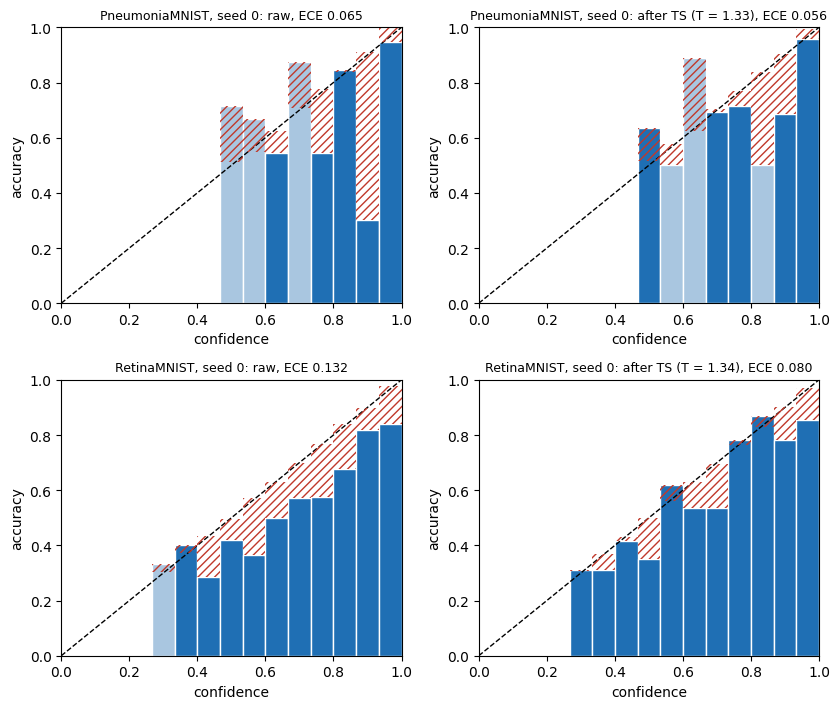

In [22]:
def quick_metrics(proba, y):
    return {"ECE": ece_score(proba, y), "NLL": nll_score(proba, y), "Brier": brier_score(proba, y), "accuracy": float((proba.argmax(1) == y).mean())}

rows = []
for flag in DATASETS:
    yv, yt = labels[flag]["val"], labels[flag]["test"]
    for s in range(N_SEEDS):
        zv, zt = STD[flag]["val"][s][None], STD[flag]["test"][s][None]
        T = fit_temperature(zv, yv)
        raw_v, raw_t = quick_metrics(ensemble_proba(zv), yv), quick_metrics(ensemble_proba(zt), yt)
        ts_v, ts_t = quick_metrics(ensemble_proba(zv, T), yv), quick_metrics(ensemble_proba(zt, T), yt)
        rows.append({"dataset": NICE[flag], "seed": s, "T": T,
                     "ECE_val_raw": raw_v["ECE"], "ECE_val_TS": ts_v["ECE"], "ECE_test_raw": raw_t["ECE"], "ECE_test_TS": ts_t["ECE"],
                     "NLL_test_raw": raw_t["NLL"], "NLL_test_TS": ts_t["NLL"], "acc_test_raw": raw_t["accuracy"], "acc_test_TS": ts_t["accuracy"]})
ts_table = pd.DataFrame(rows)
display(ts_table.round(3))
ts_table.to_csv(os.path.join(OUT_DIR, "step5_temperature_scaling_single_models.csv"), index=False)

print("\nAverage over the 5 seeds:")
display(ts_table.drop(columns="seed").groupby("dataset").mean().round(3))

fig, axes = plt.subplots(2, 2, figsize=(8.5, 7.2))
for r_, flag in enumerate(DATASETS):
    yt = labels[flag]["test"]
    zt = STD[flag]["test"][0][None]
    T0 = ts_table[(ts_table.dataset == NICE[flag]) & (ts_table.seed == 0)]["T"].iloc[0]
    plot_reliability(axes[r_][0], ensemble_proba(zt), yt, f"{NICE[flag]}, seed 0: raw, ECE {ece_score(ensemble_proba(zt), yt):.3f}")
    plot_reliability(axes[r_][1], ensemble_proba(zt, T0), yt, f"{NICE[flag]}, seed 0: after TS (T = {T0:.2f}), ECE {ece_score(ensemble_proba(zt, T0), yt):.3f}")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "figures", "step5_temperature_scaling.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 6: A deep ensemble (5 models vote)

Project 1 trained 5 models with the same setting but different seeds. Averaging their predicted probabilities gives a **deep ensemble**. When the 5 models disagree, the averaged probability becomes less extreme, which usually makes the confidence more honest. The cell below compares the average single model with the ensemble, with and without temperature scaling.

**What to look for:** does the ensemble have a lower test ECE / NLL / Brier than the average single model? (Its accuracy is often a little higher too.) Do not trust small differences yet: Step 9 puts proper confidence intervals on them.

In [23]:
rows = []
for flag in DATASETS:
    yv, yt = labels[flag]["val"], labels[flag]["test"]
    singles = [quick_metrics(ensemble_proba(STD[flag]["test"][s][None]), yt) for s in range(N_SEEDS)]
    rows.append({"dataset": NICE[flag], "method": "average of the 5 single models", **{k: np.mean([m[k] for m in singles]) for k in singles[0]}})
    ens_val, ens_test = np.stack(STD[flag]["val"]), np.stack(STD[flag]["test"])
    rows.append({"dataset": NICE[flag], "method": "ensemble of 5", **quick_metrics(ensemble_proba(ens_test), yt)})
    T_ens = fit_temperature(ens_val, yv)
    rows.append({"dataset": NICE[flag], "method": f"ensemble of 5 + TS (T = {T_ens:.2f})", **quick_metrics(ensemble_proba(ens_test, T_ens), yt)})
ens_table = pd.DataFrame(rows)
display(ens_table.round(3))

,dataset,method,ECE,NLL,Brier,accuracy
0,PneumoniaMNIST,average of the 5 single models,0.058,0.314,0.143,0.913
1,PneumoniaMNIST,ensemble of 5,0.048,0.251,0.130,0.912
2,PneumoniaMNIST,ensemble of 5 + TS (T = 0.98),0.045,0.253,0.130,0.912
3,RetinaMNIST,average of the 5 single models,0.132,1.239,0.591,0.553
4,RetinaMNIST,ensemble of 5,0.042,1.044,0.526,0.595
5,RetinaMNIST,ensemble of 5 + TS (T = 0.87),0.057,1.063,0.529,0.598


## Step 7: MC dropout (needs the GPU)

Project 1's models have no dropout, so for MC dropout we have to **train new models**. They are exactly like the reference models of Project 1 (same setting, same hyperparameters, same seeds) except for one thing: just before the final layer there is a **dropout layer** that randomly switches off 30% of the features during training.

At test time we keep that dropout layer switched **on** and predict every image 30 times. Every pass gives a slightly different answer, and we average them. We also keep the normal prediction with dropout off ("dropout, 1 pass"). This is an important control: it shows whether any improvement comes from the 30-pass averaging or just from training with dropout.

- **Quick test:** 2 models per dataset, 2 epochs, 10 passes (about 2 minutes). **Full run:** 5 models per dataset (about 5 to 8 minutes).
- Each model is saved to your Drive. If Colab disconnects, run all cells again: finished models are **loaded, not re-trained**.
- If `RUN_MC_DROPOUT = False` (no GPU), cell 7b prints a message and everything else still works.

The training code is the same as in Project 1 (data, CLAHE, augmentation, training loop), plus the dropout layer. You do not need to read it.

In [24]:
# 7a. Training code (same as Project 1, plus a dropout layer in front of the last layer).
_RAW, _PREPARED = {}, {}

def get_raw(flag):
    if flag not in _RAW:
        out = {}
        for split in ["train", "val", "test"]:
            ds = DATASETS[flag](split=split, download=True, size=IMG_SIZE)
            X = ds.imgs
            if X.ndim == 4 and X.shape[-1] == 1:
                X = X[..., 0]
            out[split] = (X, ds.labels.reshape(-1).astype(np.int64))
        assert (out["val"][1] == labels[flag]["val"]).all() and (out["test"][1] == labels[flag]["test"]).all(), "labels differ from Step 2"
        _RAW[flag] = out
    return _RAW[flag]

def apply_clahe(X, clip_limit=2.0, tile_grid=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    out = np.empty_like(X)
    for i in range(len(X)):
        img = np.ascontiguousarray(X[i])
        if img.ndim == 2:
            out[i] = clahe.apply(img)
        else:
            lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
            lightness = np.ascontiguousarray(lab[:, :, 0])
            lab[:, :, 0] = clahe.apply(lightness)
            out[i] = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    return out

def to_rgb_array(X):
    if X.ndim == 3:
        X = np.repeat(X[:, :, :, None], 3, axis=3)
    return np.ascontiguousarray(X.transpose(0, 3, 1, 2))

def get_data(flag, use_clahe):
    key = (flag, bool(use_clahe))
    if key not in _PREPARED:
        out = {}
        for split in ["train", "val", "test"]:
            X, y = get_raw(flag)[split]
            if use_clahe:
                X = apply_clahe(X)
            out[split] = (torch.from_numpy(to_rgb_array(X)), torch.from_numpy(y))
        _PREPARED[key] = out
    return _PREPARED[key]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD_IMG = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def normalize(x):
    return (x - MEAN) / STD_IMG

def augment_batch(x, max_rot_deg=10, max_shift=0.05, brightness=0.2, contrast=0.2):
    B = x.shape[0]
    dev = x.device
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    angle = (torch.rand(B, device=dev) * 2 - 1) * max_rot_deg * math.pi / 180.0
    tx = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    ty = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos, -sin, tx], dim=1), torch.stack([sin, cos, ty], dim=1)], dim=1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    b = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * brightness
    c = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * contrast
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - mean) * c + mean) * b
    return x.clamp(0, 1)

def build_model(n_classes, pretrained, p_drop):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Sequential(nn.Dropout(p=p_drop), nn.Linear(model.fc.in_features, n_classes))   # dropout + last layer
    return model.to(device)

@torch.no_grad()
def predict_logits(model, X_uint8, batch_size=256):
    """Normal prediction (dropout OFF). Returns a CPU tensor (N, C)."""
    model.eval()
    chunks = []
    for i in range(0, len(X_uint8), batch_size):
        xb = X_uint8[i:i + batch_size].to(device).float() / 255.0
        chunks.append(model(normalize(xb)).float().cpu())
    return torch.cat(chunks)

@torch.no_grad()
def predict_mc_logits(model, X_uint8, passes, batch_size=256):
    """MC dropout: only the dropout layer stays random. Returns a numpy array (passes, N, C)."""
    model.eval()
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.train()
    out = []
    for _ in range(passes):
        chunks = []
        for i in range(0, len(X_uint8), batch_size):
            xb = X_uint8[i:i + batch_size].to(device).float() / 255.0
            chunks.append(model(normalize(xb)).float().cpu())
        out.append(torch.cat(chunks))
    model.eval()
    return torch.stack(out).numpy()

def train_dropout_model(flag, cfg, seed, epochs):
    """Train ONE model with dropout. Returns normal (dropout off) and MC dropout logits for validation and test."""
    set_seed(seed)
    n_classes = N_CLASSES[flag]
    data = get_data(flag, cfg["clahe"])
    X_train, y_train = data["train"]
    X_val, y_val = data["val"]
    X_test, _ = data["test"]
    X_train_dev, y_train_dev = X_train.to(device), y_train.to(device)
    n_train = len(y_train)

    model = build_model(n_classes, cfg["pretrained"], DROPOUT_P)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    shuffler = torch.Generator().manual_seed(seed)

    best_val_loss, best_epoch, best_state = float("inf"), 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(n_train, generator=shuffler).to(device)
        for i in range(0, n_train, BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            if len(idx) < 2:
                continue
            xb = X_train_dev[idx].float() / 255.0
            yb = y_train_dev[idx]
            if cfg["augment"]:
                xb = augment_batch(xb)
            loss = F.cross_entropy(model(normalize(xb)), yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        scheduler.step()
        val_loss = F.cross_entropy(predict_logits(model, X_val), y_val).item()     # dropout OFF for choosing the epoch
        if val_loss < best_val_loss or best_state is None:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    out = {"det_val": predict_logits(model, X_val).numpy(), "det_test": predict_logits(model, X_test).numpy()}
    torch.manual_seed(10000 + seed)
    out["mc_val"] = predict_mc_logits(model, X_val, MC_PASSES)
    out["mc_test"] = predict_mc_logits(model, X_test, MC_PASSES)
    out["best_epoch"] = np.array(best_epoch)
    del model, optimizer, X_train_dev, y_train_dev
    if USE_GPU:
        torch.cuda.empty_cache()
    return out

print("Dropout training code is ready.")

Dropout training code is ready.


In [25]:
# 7b. Train (or load) the dropout models.
HAVE_MC = False
MC = {flag: {"det_val": [], "det_test": [], "mc_val": [], "mc_test": [], "best_epoch": []} for flag in DATASETS}

if not RUN_MC_DROPOUT:
    print("RUN_MC_DROPOUT is False: MC dropout is skipped. The rest of the notebook still works.")
else:
    t_start = time.time()
    for flag in DATASETS:
        cfg = REF[flag]
        for s in range(N_SEEDS_MC):
            path = os.path.join(OUT_DIR, "mc_logits", f"{flag}__{cfg['config']}__p{DROPOUT_P}__seed{s}.npz")
            if os.path.exists(path):
                z = np.load(path)
                out = {k: z[k] for k in z.files}
                status = "loaded from Drive"
            else:
                out = train_dropout_model(flag, cfg, s, MC_EPOCHS[flag])
                np.savez_compressed(path, **out)
                status = "trained and saved"
            for k in ["det_val", "det_test", "mc_val", "mc_test"]:
                MC[flag][k].append(np.asarray(out[k], dtype=np.float64))
            MC[flag]["best_epoch"].append(int(out["best_epoch"]))
            acc = (MC[flag]["det_test"][-1].argmax(1) == labels[flag]["test"]).mean()
            print(f"{NICE[flag]:15s} seed {s}: {status:18s} | chosen epoch {int(out['best_epoch']):2d} | test accuracy (dropout off) {acc:.3f} | {(time.time() - t_start) / 60:.1f} min so far")
    HAVE_MC = True
    print("\nDropout models are ready.")

PneumoniaMNIST  seed 0: loaded from Drive  | chosen epoch  5 | test accuracy (dropout off) 0.894 | 0.0 min so far
PneumoniaMNIST  seed 1: loaded from Drive  | chosen epoch  7 | test accuracy (dropout off) 0.872 | 0.0 min so far
PneumoniaMNIST  seed 2: loaded from Drive  | chosen epoch  5 | test accuracy (dropout off) 0.921 | 0.0 min so far
PneumoniaMNIST  seed 3: loaded from Drive  | chosen epoch 13 | test accuracy (dropout off) 0.936 | 0.0 min so far
PneumoniaMNIST  seed 4: loaded from Drive  | chosen epoch  7 | test accuracy (dropout off) 0.923 | 0.1 min so far
RetinaMNIST     seed 0: loaded from Drive  | chosen epoch  4 | test accuracy (dropout off) 0.560 | 0.1 min so far
RetinaMNIST     seed 1: loaded from Drive  | chosen epoch  4 | test accuracy (dropout off) 0.560 | 0.1 min so far
RetinaMNIST     seed 2: loaded from Drive  | chosen epoch  2 | test accuracy (dropout off) 0.550 | 0.1 min so far
RetinaMNIST     seed 3: loaded from Drive  | chosen epoch  3 | test accuracy (dropout of

## Step 8: Compare all methods (Table 1)

Now we put everything side by side. Every method makes its prediction by averaging *M* sets of raw scores:

| Method | What it is |
|---|---|
| `single` | one Project 1 model (M = 1), 5 seeds |
| `single + TS` | the same, after temperature scaling |
| `dropout (1 pass)` | a dropout-trained model used normally (control) |
| `MC dropout` | a dropout-trained model, 30 random passes averaged |
| `MC dropout + TS` | the same, after temperature scaling |
| `ensemble` | the 5 Project 1 models averaged (one ensemble) |
| `ensemble + TS` | the same, after temperature scaling |

All temperatures are fitted on the validation set only. Scores are on the **test set**.

**How to read Table 1:** for methods with several seeds the cell shows *mean +/- standard deviation over the seeds* (how much training randomness moves the result). The ensemble is a single model, so it shows one number. Columns: `ECE`, `NLL`, `Brier` (calibration, lower is better), `accuracy`, the main Project 1 score (`AUC` or `QWK`, higher is better), and `AURC` (referral quality, lower is better). Do not decide anything from small differences here: Step 9 adds proper confidence intervals.

In [26]:
METHOD_ORDER = ["single", "single + TS", "dropout (1 pass)", "MC dropout", "MC dropout + TS", "ensemble", "ensemble + TS"]

# 8a. Collect the raw scores of every method: a list with one (M, N, C) array per seed.
LOGITS = {flag: {} for flag in DATASETS}
for flag in DATASETS:
    LOGITS[flag]["single"] = {"val": [z[None] for z in STD[flag]["val"]], "test": [z[None] for z in STD[flag]["test"]]}
    LOGITS[flag]["ensemble"] = {"val": [np.stack(STD[flag]["val"])], "test": [np.stack(STD[flag]["test"])]}
    if HAVE_MC:
        LOGITS[flag]["dropout (1 pass)"] = {"val": [z[None] for z in MC[flag]["det_val"]], "test": [z[None] for z in MC[flag]["det_test"]]}
        LOGITS[flag]["MC dropout"] = {"val": MC[flag]["mc_val"], "test": MC[flag]["mc_test"]}

# 8b. Probabilities of every method, and the same after temperature scaling (T fitted on VALIDATION only).
PROBS = {flag: {} for flag in DATASETS}
TEMPS = {flag: {} for flag in DATASETS}
for flag in DATASETS:
    yv = labels[flag]["val"]
    for name, d in LOGITS[flag].items():
        PROBS[flag][name] = {"val": [ensemble_proba(z) for z in d["val"]], "test": [ensemble_proba(z) for z in d["test"]]}
        if name != "dropout (1 pass)":
            temps = [fit_temperature(z, yv) for z in d["val"]]
            TEMPS[flag][name] = temps
            PROBS[flag][name + " + TS"] = {"val": [ensemble_proba(z, t) for z, t in zip(d["val"], temps)],
                                           "test": [ensemble_proba(z, t) for z, t in zip(d["test"], temps)]}

# 8c. Scores of every method on the test set.
def full_metrics(flag, proba):
    y = labels[flag]["test"]
    conf, pred = proba.max(1), proba.argmax(1)
    correct = (pred == y).astype(float)
    if N_CLASSES[flag] == 2:
        primary = roc_auc_score(y, proba[:, 1])
    else:
        primary = cohen_kappa_score(y, pred, weights="quadratic")
    return {"ECE": ece_score(proba, y), "NLL": nll_score(proba, y), "Brier": brier_score(proba, y),
            "accuracy": correct.mean(), PRIMARY_NAME[flag]: primary, "AURC": aurc_score(conf, correct, NOISE[flag])}

T1_MEAN, T1_SD, T1_STR = {}, {}, {}
for flag in DATASETS:
    names = [n for n in METHOD_ORDER if n in PROBS[flag]]
    per_seed = {n: pd.DataFrame([full_metrics(flag, p) for p in PROBS[flag][n]["test"]]) for n in names}
    T1_MEAN[flag] = pd.DataFrame({n: per_seed[n].mean() for n in names}).T
    T1_SD[flag] = pd.DataFrame({n: per_seed[n].std(ddof=1) if len(per_seed[n]) > 1 else per_seed[n].mean() * np.nan for n in names}).T
    T1_STR[flag] = T1_MEAN[flag].copy().astype(object)
    for n in names:
        for c in T1_MEAN[flag].columns:
            m, s_ = T1_MEAN[flag].loc[n, c], T1_SD[flag].loc[n, c]
            T1_STR[flag].loc[n, c] = f"{m:.3f}" if np.isnan(s_) else f"{m:.3f} +/- {s_:.3f}"
    T1_STR[flag].insert(0, "models", [len(per_seed[n]) for n in names])
    T1_STR[flag].index.name = "method"
    print("=" * 90)
    print(f"{NICE[flag]}  (test set; mean +/- standard deviation over seeds; reference setting: {REF[flag]['config']})")
    display(T1_STR[flag])
    T1_STR[flag].to_csv(os.path.join(OUT_DIR, f"table1_{flag}.csv"))
    print("Temperatures fitted on the validation set:", {n: np.round(t, 2).tolist() for n, t in TEMPS[flag].items()})

PneumoniaMNIST  (test set; mean +/- standard deviation over seeds; reference setting: pretrained+aug)


,models,ECE,NLL,Brier,accuracy,AUC,AURC
method,,,,,,,
single,5,0.058 +/- 0.011,0.314 +/- 0.067,0.143 +/- 0.021,0.913 +/- 0.013,0.984 +/- 0.005,0.018 +/- 0.006
single + TS,5,0.052 +/- 0.010,0.279 +/- 0.063,0.139 +/- 0.021,0.913 +/- 0.013,0.984 +/- 0.005,0.018 +/- 0.006
dropout (1 pass),5,0.061 +/- 0.017,0.304 +/- 0.076,0.146 +/- 0.036,0.909 +/- 0.026,0.986 +/- 0.004,0.018 +/- 0.008
MC dropout,5,0.059 +/- 0.017,0.301 +/- 0.076,0.145 +/- 0.036,0.909 +/- 0.026,0.986 +/- 0.004,0.018 +/- 0.008
MC dropout + TS,5,0.056 +/- 0.020,0.278 +/- 0.079,0.143 +/- 0.036,0.909 +/- 0.026,0.986 +/- 0.004,0.018 +/- 0.008
ensemble,1,0.048,0.251,0.130,0.912,0.988,0.015
ensemble + TS,1,0.045,0.253,0.130,0.912,0.988,0.015


Temperatures fitted on the validation set: {'single': [1.33, 0.93, 1.2, 1.26, 1.27], 'ensemble': [0.98], 'MC dropout': [1.08, 1.09, 1.21, 1.37, 1.01]}
RetinaMNIST  (test set; mean +/- standard deviation over seeds; reference setting: pretrained+aug+clahe)


,models,ECE,NLL,Brier,accuracy,QWK,AURC
method,,,,,,,
single,5,0.132 +/- 0.026,1.239 +/- 0.051,0.591 +/- 0.011,0.553 +/- 0.011,0.579 +/- 0.043,0.251 +/- 0.016
single + TS,5,0.092 +/- 0.012,1.158 +/- 0.011,0.574 +/- 0.008,0.553 +/- 0.011,0.579 +/- 0.043,0.251 +/- 0.016
dropout (1 pass),5,0.120 +/- 0.042,1.229 +/- 0.058,0.581 +/- 0.019,0.539 +/- 0.028,0.547 +/- 0.071,0.256 +/- 0.017
MC dropout,5,0.112 +/- 0.036,1.205 +/- 0.048,0.579 +/- 0.016,0.541 +/- 0.023,0.550 +/- 0.065,0.256 +/- 0.016
MC dropout + TS,5,0.095 +/- 0.030,1.178 +/- 0.051,0.573 +/- 0.011,0.541 +/- 0.023,0.550 +/- 0.065,0.256 +/- 0.016
ensemble,1,0.042,1.044,0.526,0.595,0.588,0.216
ensemble + TS,1,0.057,1.063,0.529,0.598,0.589,0.216


Temperatures fitted on the validation set: {'single': [1.34, 1.09, 1.28, 1.47, 1.1], 'ensemble': [0.87], 'MC dropout': [1.3, 1.24, 0.95, 0.93, 1.14]}


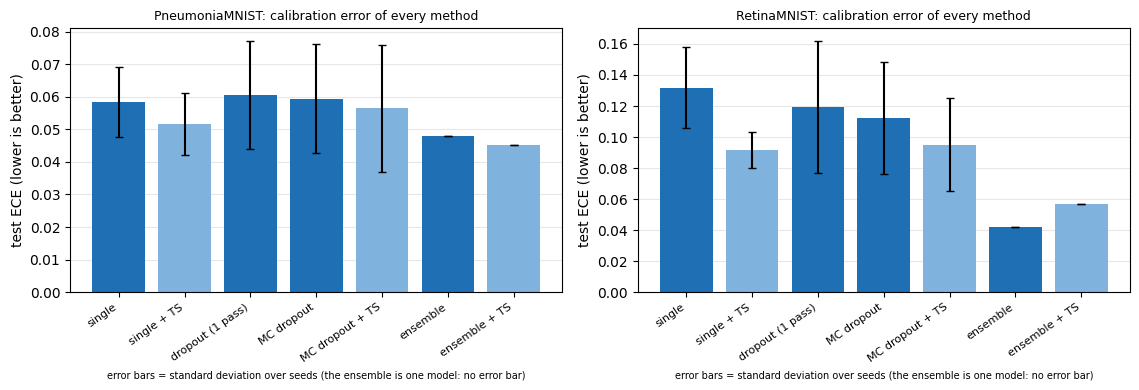

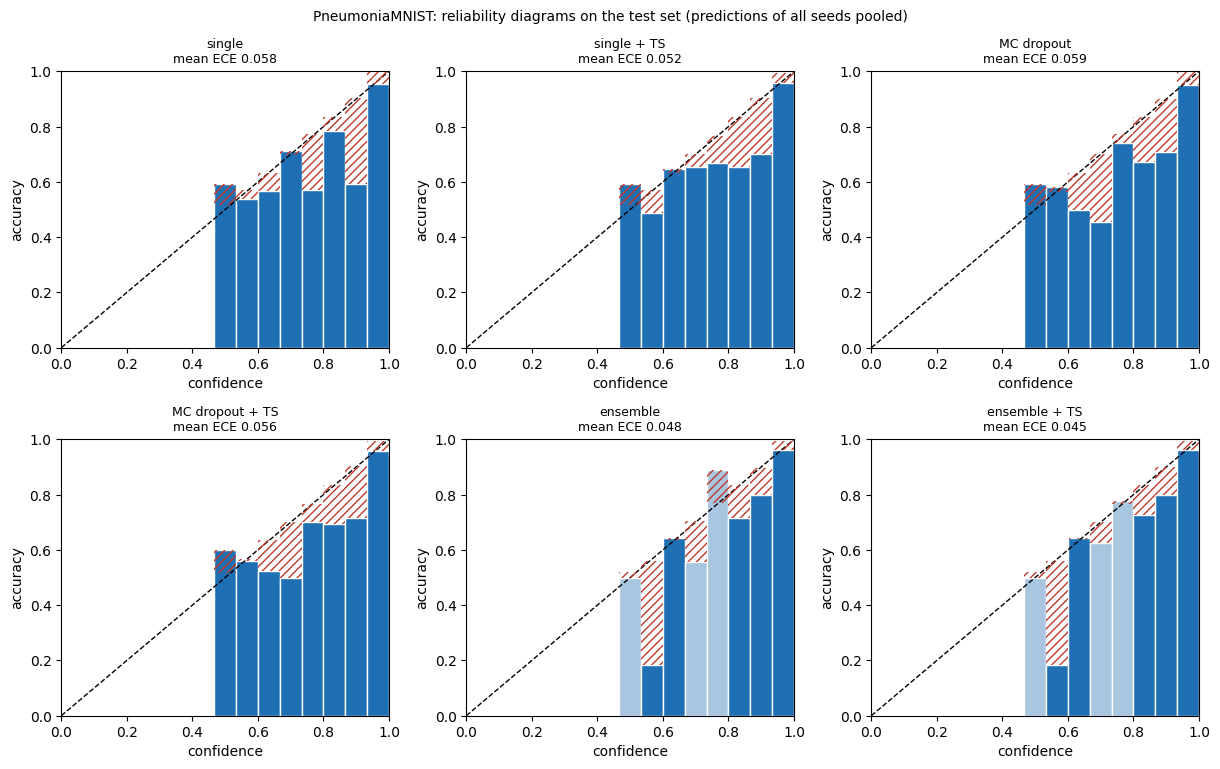

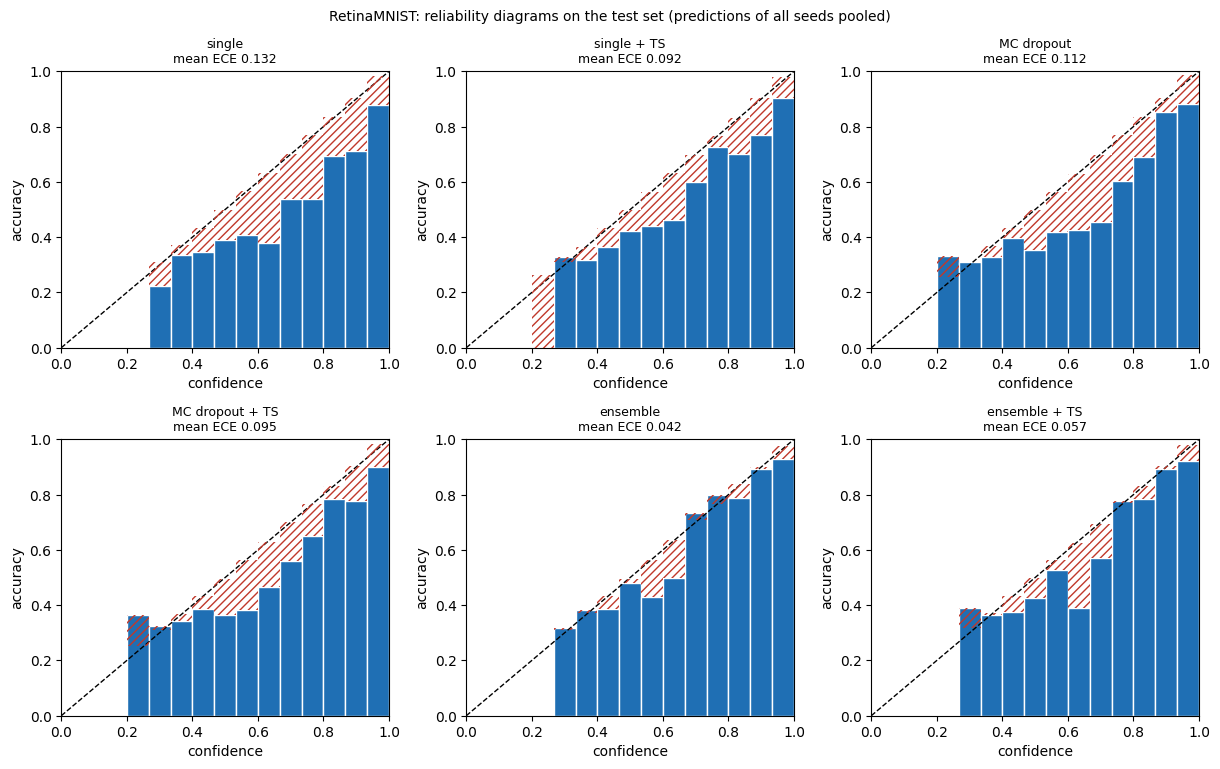

In [27]:
def plot_ece_bars():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
    for ax, flag in zip(axes, DATASETS):
        names = list(T1_MEAN[flag].index)
        means = T1_MEAN[flag]["ECE"].values
        sds = np.nan_to_num(T1_SD[flag]["ECE"].values)
        colors = ["#1f6fb4" if "TS" not in n else "#7fb2dd" for n in names]
        ax.bar(range(len(names)), means, yerr=sds, color=colors, capsize=3, zorder=2)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, rotation=35, ha="right", fontsize=8)
        ax.set_ylabel("test ECE (lower is better)")
        ax.set_xlabel("error bars = standard deviation over seeds (the ensemble is one model: no error bar)", fontsize=7)
        ax.set_title(f"{NICE[flag]}: calibration error of every method", fontsize=9)
        ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", "ece_by_method.png"), dpi=150, bbox_inches="tight")
    plt.show()

def reliability_grid(flag):
    names = [n for n in ["single", "single + TS", "MC dropout", "MC dropout + TS", "ensemble", "ensemble + TS"] if n in PROBS[flag]]
    y = labels[flag]["test"]
    ncol = 3
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.1 * ncol, 3.9 * nrow), squeeze=False)
    for ax, name in zip(axes.ravel(), names):
        plist = PROBS[flag][name]["test"]
        pooled, ypool = np.concatenate(plist), np.tile(y, len(plist))
        mean_ece = np.mean([ece_score(p, y) for p in plist])
        plot_reliability(ax, pooled, ypool, f"{name}\nmean ECE {mean_ece:.3f}")
    for ax in axes.ravel()[len(names):]:
        ax.axis("off")
    fig.suptitle(f"{NICE[flag]}: reliability diagrams on the test set (predictions of all seeds pooled)", fontsize=10)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "figures", f"reliability_{flag}.png"), dpi=150, bbox_inches="tight")
    plt.show()

plot_ece_bars()
for flag in DATASETS:
    reliability_grid(flag)

## Step 9: Does it really help? (paired bootstrap)

Differences in Table 1 can be luck, because the test sets are small (a few hundred images). To measure that, we use a **bootstrap over the test images**:

1. Draw a new test set of the same size *with replacement* from the real one (some images appear twice, some never).
2. Compute the scores of both methods on that new test set. For methods with several seeds we average the seeds.
3. Repeat many times (`N_BOOT`). The middle 95% of the differences is the **95% confidence interval**.

Because both methods are scored on the *same* redrawn images each time ("paired"), the comparison is fair. The result is a difference **A minus B**. For ECE, NLL, Brier and AURC, *negative means A is better*; for accuracy, positive means A is better. If the interval contains 0, **you cannot claim a difference**.

What this does and does not capture: it captures the luck of *which test images we have*. It does not capture a different patient population. Ties to Project 1: this is the test-set uncertainty that the Project 1 report listed as a limitation.

In [28]:
BOOT_METRICS = ["ECE", "NLL", "Brier", "AURC", "accuracy"]

def metric_vector(proba, y, noise):
    conf, pred = proba.max(1), proba.argmax(1)
    correct = (pred == y).astype(float)
    return np.array([ece_score(proba, y), nll_score(proba, y), brier_score(proba, y), aurc_score(conf, correct, noise), correct.mean()])

def bootstrap_all(flag, n_boot, seed=2025):
    """For every method: the 5 scores on the full test set and on n_boot redrawn test sets (averaged over the seeds)."""
    y, noise = labels[flag]["test"], NOISE[flag]
    n = len(y)
    idx_all = np.random.default_rng(seed).integers(0, n, size=(n_boot, n))
    point, boot = {}, {}
    for name, d in PROBS[flag].items():
        arr = np.zeros((len(d["test"]), n_boot, len(BOOT_METRICS)))
        pts = []
        for s, proba in enumerate(d["test"]):
            pts.append(metric_vector(proba, y, noise))
            for b in range(n_boot):
                idx = idx_all[b]
                arr[s, b] = metric_vector(proba[idx], y[idx], noise[idx])
        point[name], boot[name] = np.mean(pts, axis=0), arr.mean(axis=0)
    return point, boot

PAIRS = [
    ("single + TS", "single", "temperature scaling on a single model"),
    ("ensemble", "single", "ensemble of 5 vs a single model"),
    ("ensemble + TS", "single + TS", "ensemble vs single model, both temperature-scaled"),
    ("ensemble + TS", "ensemble", "temperature scaling on the ensemble"),
    ("MC dropout", "dropout (1 pass)", "30 MC passes vs 1 pass of the same dropout-trained models"),
    ("MC dropout", "single", "MC dropout vs a standard single model"),
    ("MC dropout + TS", "MC dropout", "temperature scaling on MC dropout"),
    ("MC dropout", "ensemble", "MC dropout vs the ensemble"),
]

def fmt_ci(point, lo, hi):
    return f"{point:+.3f} [{lo:+.3f}, {hi:+.3f}]"

T2 = {}
POINT, BOOT = {}, {}
for flag in DATASETS:
    POINT[flag], BOOT[flag] = bootstrap_all(flag, N_BOOT)
    rows = []
    for a, b, text in PAIRS:
        if a not in POINT[flag] or b not in POINT[flag]:
            continue
        row = {"comparison (A vs B)": f"{a}  vs  {b}", "what it tests": text}
        better, worse, unclear = [], [], []
        for j, m in enumerate(BOOT_METRICS):
            diff = BOOT[flag][a][:, j] - BOOT[flag][b][:, j]
            lo, hi = np.percentile(diff, [2.5, 97.5])
            row[m] = fmt_ci(POINT[flag][a][j] - POINT[flag][b][j], lo, hi)
            lower_is_better = m != "accuracy"
            if hi < 0:
                (better if lower_is_better else worse).append(m)
            elif lo > 0:
                (worse if lower_is_better else better).append(m)
            else:
                unclear.append(m)
        row["A clearly better on"] = ", ".join(better) or "-"
        row["A clearly worse on"] = ", ".join(worse) or "-"
        rows.append(row)
    T2[flag] = pd.DataFrame(rows)
    print("=" * 100)
    print(f"{NICE[flag]}: difference A minus B, with 95% bootstrap interval over the test images ({N_BOOT} redraws)")
    display(T2[flag])
    T2[flag].to_csv(os.path.join(OUT_DIR, f"table2_differences_{flag}.csv"), index=False)

PneumoniaMNIST: difference A minus B, with 95% bootstrap interval over the test images (1000 redraws)


,comparison (A vs B),what it tests,ECE,NLL,Brier,AURC,accuracy,A clearly better on,A clearly worse on
0,single + TS vs single,temperature scaling on a single model,"-0.007 [-0.010, -0.003]","-0.035 [-0.049, -0.022]","-0.004 [-0.005, -0.002]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","ECE, NLL, Brier",-
1,ensemble vs single,ensemble of 5 vs a single model,"-0.011 [-0.018, -0.001]","-0.063 [-0.081, -0.045]","-0.014 [-0.017, -0.010]","-0.003 [-0.004, -0.002]","-0.002 [-0.010, +0.006]","ECE, NLL, Brier, AURC",-
2,ensemble + TS vs single + TS,"ensemble vs single model, both temperature-scaled","-0.007 [-0.013, +0.005]","-0.026 [-0.037, -0.016]","-0.010 [-0.013, -0.006]","-0.003 [-0.004, -0.002]","-0.002 [-0.010, +0.006]","NLL, Brier, AURC",-
3,ensemble + TS vs ensemble,temperature scaling on the ensemble,"-0.003 [-0.005, +0.003]","+0.002 [+0.001, +0.003]","+0.000 [+0.000, +0.000]","+0.000 [-0.000, +0.000]","+0.000 [+0.000, +0.000]",-,"NLL, Brier"
4,MC dropout vs dropout (1 pass),30 MC passes vs 1 pass of the same dropout-tra...,"-0.001 [-0.004, +0.001]","-0.003 [-0.005, -0.002]","-0.000 [-0.000, -0.000]","+0.000 [-0.000, +0.000]","-0.000 [-0.001, +0.001]","NLL, Brier",-
5,MC dropout vs single,MC dropout vs a standard single model,"+0.001 [-0.005, +0.007]","-0.013 [-0.028, +0.000]","+0.002 [-0.004, +0.008]","-0.000 [-0.002, +0.001]","-0.004 [-0.011, +0.002]",-,-
6,MC dropout + TS vs MC dropout,temperature scaling on MC dropout,"-0.003 [-0.006, -0.001]","-0.023 [-0.034, -0.014]","-0.002 [-0.003, -0.001]","-0.000 [-0.000, +0.000]","+0.000 [+0.000, +0.000]","ECE, NLL, Brier",-
7,MC dropout vs ensemble,MC dropout vs the ensemble,"+0.012 [+0.002, +0.019]","+0.049 [+0.033, +0.068]","+0.016 [+0.010, +0.022]","+0.002 [+0.001, +0.004]","-0.003 [-0.013, +0.006]",-,"ECE, NLL, Brier, AURC"


RetinaMNIST: difference A minus B, with 95% bootstrap interval over the test images (1000 redraws)


,comparison (A vs B),what it tests,ECE,NLL,Brier,AURC,accuracy,A clearly better on,A clearly worse on
0,single + TS vs single,temperature scaling on a single model,"-0.040 [-0.044, -0.019]","-0.081 [-0.105, -0.059]","-0.017 [-0.022, -0.012]","-0.000 [-0.001, +0.001]","+0.000 [+0.000, +0.000]","ECE, NLL, Brier",-
1,ensemble vs single,ensemble of 5 vs a single model,"-0.090 [-0.098, -0.037]","-0.195 [-0.226, -0.166]","-0.065 [-0.070, -0.060]","-0.035 [-0.047, -0.022]","+0.042 [+0.019, +0.065]","ECE, NLL, Brier, AURC, accuracy",-
2,ensemble + TS vs single + TS,"ensemble vs single model, both temperature-scaled","-0.035 [-0.053, -0.000]","-0.095 [-0.118, -0.073]","-0.044 [-0.053, -0.036]","-0.035 [-0.047, -0.022]","+0.045 [+0.022, +0.067]","ECE, NLL, Brier, AURC, accuracy",-
3,ensemble + TS vs ensemble,temperature scaling on the ensemble,"+0.014 [-0.020, +0.036]","+0.018 [+0.008, +0.029]","+0.003 [+0.001, +0.006]","+0.000 [-0.002, +0.002]","+0.003 [-0.005, +0.012]",-,"NLL, Brier"
4,MC dropout vs dropout (1 pass),30 MC passes vs 1 pass of the same dropout-tra...,"-0.007 [-0.016, +0.006]","-0.023 [-0.036, -0.012]","-0.002 [-0.004, -0.001]","-0.000 [-0.002, +0.002]","+0.003 [-0.003, +0.009]","NLL, Brier",-
5,MC dropout vs single,MC dropout vs a standard single model,"-0.020 [-0.037, +0.004]","-0.034 [-0.088, +0.016]","-0.012 [-0.030, +0.006]","+0.005 [-0.012, +0.020]","-0.011 [-0.031, +0.008]",-,-
6,MC dropout + TS vs MC dropout,temperature scaling on MC dropout,"-0.017 [-0.027, -0.005]","-0.027 [-0.039, -0.017]","-0.006 [-0.008, -0.004]","+0.000 [-0.001, +0.001]","+0.000 [+0.000, +0.000]","ECE, NLL, Brier",-
7,MC dropout vs ensemble,MC dropout vs the ensemble,"+0.070 [+0.023, +0.085]","+0.161 [+0.109, +0.217]","+0.053 [+0.035, +0.071]","+0.040 [+0.020, +0.059]","-0.053 [-0.085, -0.022]",-,"ECE, NLL, Brier, AURC, accuracy"


## Step 10: Selective referral ("refer to a clinician")

Now the practical question. If the model answers only the cases it is most sure about and refers the rest, how good are its answers?

**10a. Risk-coverage curves.** x = share of cases the model answers (coverage), y = its error rate on those cases. **Lower is better.** Read the plot from the right (answer everything: the normal error rate) towards the left (answer only the most confident cases). The dashed grey line is "refer cases at random": it does not improve anything. The dotted black line is a **perfect** ranking for the single models (all of their mistakes referred first). A good method falls quickly as coverage drops and stays close to the dotted line. A method that makes fewer mistakes overall (for example a good ensemble) can lie below the dotted line near 100% coverage, because its own error rate is lower.

**10b. Accuracy at fixed coverage.** The same information as numbers: "if the model answers only its most confident 80% of cases, its accuracy there is ...". For RetinaMNIST we also show the QWK on the answered cases.

**10c. Which uncertainty score is best?** The highest probability, the entropy, and (for ensembles and MC dropout) the mutual information, which measures *disagreement* between the opinions. The table shows the AURC of each (lower is better). With two classes, entropy and highest probability rank the cases in exactly the same order, so they give identical numbers.

**10d. Can a threshold chosen on validation be used on the test set?** In practice you must choose the confidence threshold **before** you see the test cases. Here we choose it on the validation set so that, say, 80% of the validation cases are answered, then apply it to the test set and see what really happens: how many test cases are answered (coverage), how accurate they are, and how accurate the *referred* cases would have been. If the test coverage is far from the target, the threshold does not transfer (a sign of a shift between validation and test).

Remember from the ideas section: for a single model with only two classes, temperature scaling cannot change the ranking of the cases, so `single` and `single + TS` have the **same** AURC for PneumoniaMNIST. Honest probabilities and a good referral ranking are different goals.

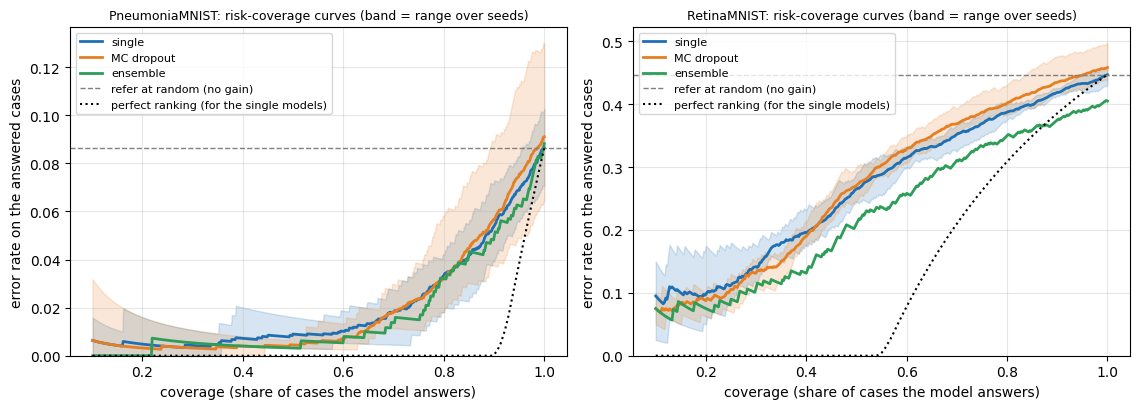

In [29]:
RC_METHODS = [n for n in ["single", "MC dropout", "ensemble"] if n in PROBS["pneumoniamnist"]]
RC_COLORS = {"single": "#1f6fb4", "MC dropout": "#e67e22", "ensemble": "#2e9d57"}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, flag in zip(axes, DATASETS):
    y, noise = labels[flag]["test"], NOISE[flag]
    for name in RC_METHODS:
        curves = []
        for proba in PROBS[flag][name]["test"]:
            cov, risk = selective_curve(proba.max(1), (proba.argmax(1) == y).astype(float), noise)
            curves.append(risk)
        curves = np.array(curves)
        show = cov >= 0.10                                   # the far left has very few cases: too noisy to show
        ax.plot(cov[show], curves.mean(0)[show], color=RC_COLORS[name], lw=2, label=name)
        if len(curves) > 1:
            ax.fill_between(cov[show], curves.min(0)[show], curves.max(0)[show], color=RC_COLORS[name], alpha=0.18)
    base = PROBS[flag]["single"]["test"]
    err_all = np.mean([(p.argmax(1) != y).mean() for p in base])
    oracle = np.mean([selective_curve((p.argmax(1) == y).astype(float), (p.argmax(1) == y).astype(float), noise)[1] for p in base], axis=0)
    ax.axhline(err_all, color="grey", ls="--", lw=1, label="refer at random (no gain)")
    ax.plot(cov[cov >= 0.10], oracle[cov >= 0.10], color="black", ls=":", lw=1.5, label="perfect ranking (for the single models)")
    ax.set_xlabel("coverage (share of cases the model answers)")
    ax.set_ylabel("error rate on the answered cases")
    ax.set_title(f"{NICE[flag]}: risk-coverage curves (band = range over seeds)", fontsize=9)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "figures", "risk_coverage.png"), dpi=150, bbox_inches="tight")
plt.show()

In [30]:
COVS = [1.0, 0.9, 0.8, 0.7, 0.5]
SEL_ACC, SEL_QWK = {}, {}
for flag in DATASETS:
    y, noise = labels[flag]["test"], NOISE[flag]
    names = [n for n in METHOD_ORDER if n in PROBS[flag]]
    acc_rows, qwk_rows = [], []
    for name in names:
        accs = {c: [] for c in COVS}
        qwks = {c: [] for c in COVS}
        for proba in PROBS[flag][name]["test"]:
            conf, pred = proba.max(1), proba.argmax(1)
            correct = (pred == y).astype(float)
            for c in COVS:
                accs[c].append(accuracy_at(conf, correct, noise, c))
                if flag == "retinamnist":
                    qwks[c].append(qwk_at(conf, pred, y, noise, c))
        acc_rows.append({"method": name, **{f"answer {int(c * 100)}%": np.mean(accs[c]) for c in COVS}})
        if flag == "retinamnist":
            qwk_rows.append({"method": name, **{f"answer {int(c * 100)}%": np.nanmean(qwks[c]) for c in COVS}})
    SEL_ACC[flag] = pd.DataFrame(acc_rows).set_index("method")
    print("=" * 90)
    print(f"{NICE[flag]}: ACCURACY on the answered cases when the model answers only its most confident share of cases")
    display(SEL_ACC[flag].round(3))
    SEL_ACC[flag].to_csv(os.path.join(OUT_DIR, f"selective_accuracy_{flag}.csv"))
    if flag == "retinamnist":
        SEL_QWK[flag] = pd.DataFrame(qwk_rows).set_index("method")
        print(f"{NICE[flag]}: QWK on the answered cases")
        display(SEL_QWK[flag].round(3))
        SEL_QWK[flag].to_csv(os.path.join(OUT_DIR, f"selective_qwk_{flag}.csv"))

PneumoniaMNIST: ACCURACY on the answered cases when the model answers only its most confident share of cases


,answer 100%,answer 90%,answer 80%,answer 70%,answer 50%
method,,,,,
single,0.913,0.946,0.967,0.982,0.991
single + TS,0.913,0.946,0.967,0.982,0.991
dropout (1 pass),0.909,0.943,0.968,0.982,0.996
MC dropout,0.909,0.943,0.968,0.982,0.996
MC dropout + TS,0.909,0.943,0.968,0.982,0.996
ensemble,0.912,0.950,0.968,0.986,0.997
ensemble + TS,0.912,0.950,0.968,0.984,0.997


RetinaMNIST: ACCURACY on the answered cases when the model answers only its most confident share of cases


,answer 100%,answer 90%,answer 80%,answer 70%,answer 50%
method,,,,,
single,0.553,0.581,0.612,0.648,0.735
single + TS,0.553,0.581,0.614,0.646,0.737
dropout (1 pass),0.539,0.566,0.598,0.631,0.726
MC dropout,0.542,0.565,0.598,0.631,0.729
MC dropout + TS,0.542,0.564,0.599,0.631,0.727
ensemble,0.595,0.625,0.650,0.689,0.790
ensemble + TS,0.598,0.625,0.650,0.696,0.790


RetinaMNIST: QWK on the answered cases


,answer 100%,answer 90%,answer 80%,answer 70%,answer 50%
method,,,,,
single,0.579,0.604,0.638,0.662,0.719
single + TS,0.579,0.607,0.641,0.661,0.725
dropout (1 pass),0.547,0.578,0.607,0.632,0.681
MC dropout,0.550,0.575,0.610,0.632,0.698
MC dropout + TS,0.550,0.575,0.613,0.636,0.694
ensemble,0.588,0.664,0.678,0.683,0.766
ensemble + TS,0.589,0.666,0.678,0.699,0.754


In [31]:
# 10c. Which uncertainty score ranks the cases best? (AURC, lower is better; raw probabilities, no temperature scaling)
UNC = {}
for flag in DATASETS:
    y, noise = labels[flag]["test"], NOISE[flag]
    correct_cache = {}
    rows = []
    for name in [n for n in ["single", "MC dropout", "ensemble"] if n in LOGITS[flag]]:
        per_score = {}
        for z in LOGITS[flag][name]["test"]:
            pred = ensemble_proba(z).argmax(1)
            correct = (pred == y).astype(float)
            for sname, conf in confidence_scores(z).items():
                per_score.setdefault(sname, []).append(aurc_score(conf, correct, noise))
        rows.append({"method": name, **{s: np.mean(v) for s, v in per_score.items()}})
    UNC[flag] = pd.DataFrame(rows).set_index("method")
    print(f"{NICE[flag]}: AURC by uncertainty score (lower is better)")
    display(UNC[flag].round(4))
    UNC[flag].to_csv(os.path.join(OUT_DIR, f"uncertainty_scores_{flag}.csv"))

PneumoniaMNIST: AURC by uncertainty score (lower is better)


,highest probability,(negative) entropy,(negative) mutual information
method,,,
single,0.0183,0.0183,NaN
MC dropout,0.0178,0.0178,0.0190
ensemble,0.0154,0.0154,0.0167


RetinaMNIST: AURC by uncertainty score (lower is better)


,highest probability,(negative) entropy,(negative) mutual information
method,,,
single,0.2509,0.2527,NaN
MC dropout,0.2555,0.2575,0.2953
ensemble,0.2158,0.2187,0.2679


In [32]:
# 10d. A confidence threshold chosen on the VALIDATION set, applied to the TEST set.
TARGETS = [0.9, 0.8, 0.7]
THR = {}
for flag in DATASETS:
    y = labels[flag]["test"]
    rows = []
    for name in [n for n in ["single", "MC dropout", "ensemble"] if n in PROBS[flag]]:
        for tgt in TARGETS:
            cov_t, acc_keep, acc_ref, acc_all = [], [], [], []
            for pv, pt in zip(PROBS[flag][name]["val"], PROBS[flag][name]["test"]):
                thr = np.quantile(pv.max(1), 1 - tgt)               # keeps about `tgt` of the validation cases
                keep = pt.max(1) >= thr
                correct = pt.argmax(1) == y
                cov_t.append(keep.mean())
                acc_keep.append(correct[keep].mean() if keep.any() else np.nan)
                acc_ref.append(correct[~keep].mean() if (~keep).any() else np.nan)
                acc_all.append(correct.mean())
            rows.append({"method": name, "target coverage (validation)": tgt, "real coverage (test)": np.nanmean(cov_t),
                         "accuracy of answered cases": np.nanmean(acc_keep), "accuracy of referred cases": np.nanmean(acc_ref),
                         "accuracy without referral": np.mean(acc_all)})
    THR[flag] = pd.DataFrame(rows)
    print(f"{NICE[flag]}: threshold chosen on validation, applied to test")
    display(THR[flag].round(3))
    THR[flag].to_csv(os.path.join(OUT_DIR, f"threshold_transfer_{flag}.csv"), index=False)

PneumoniaMNIST: threshold chosen on validation, applied to test


,method,target coverage (validation),real coverage (test),accuracy of answered cases,accuracy of referred cases,accuracy without referral
0,single,0.9,0.797,0.968,0.699,0.913
1,single,0.8,0.696,0.982,0.758,0.913
2,single,0.7,0.606,0.989,0.796,0.913
3,MC dropout,0.9,0.798,0.967,0.679,0.909
4,MC dropout,0.8,0.704,0.981,0.740,0.909
5,MC dropout,0.7,0.628,0.991,0.772,0.909
6,ensemble,0.9,0.796,0.968,0.693,0.912
7,ensemble,0.8,0.694,0.988,0.738,0.912
8,ensemble,0.7,0.607,0.992,0.788,0.912


RetinaMNIST: threshold chosen on validation, applied to test


,method,target coverage (validation),real coverage (test),accuracy of answered cases,accuracy of referred cases,accuracy without referral
0,single,0.9,0.880,0.589,0.287,0.553
1,single,0.8,0.787,0.619,0.307,0.553
2,single,0.7,0.703,0.647,0.329,0.553
3,MC dropout,0.9,0.882,0.572,0.322,0.542
4,MC dropout,0.8,0.785,0.606,0.309,0.542
5,MC dropout,0.7,0.695,0.629,0.343,0.542
6,ensemble,0.9,0.890,0.632,0.295,0.595
7,ensemble,0.8,0.800,0.650,0.375,0.595
8,ensemble,0.7,0.645,0.717,0.373,0.595


## Step 11: Package everything for GitHub

This cell writes `results_tables.md` (all tables, ready to paste into your README) and creates `github_upload.zip` with the small files you should upload: the tables, figures, environment file, and a small `inputs_from_project1` folder (`results.csv` plus the 10 prediction files this notebook used) so that anybody can re-run your notebook without re-running Project 1. It will also start a download of the zip file in Colab.

In [33]:
def df_to_markdown(d, index=True):
    d = d.reset_index() if index else d
    cols = list(d.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r_ in d.iterrows():
        cells = [f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v) for v in r_.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

parts = ["# Results tables (auto-generated)\n",
         f"Run: `{RUN_NAME}`. Test-set scores. Reference settings from Project 1: " +
         ", ".join(f"{NICE[f]} = `{REF[f]['config']}`" for f in DATASETS) + ".\n"]
for flag in DATASETS:
    parts.append(f"\n## {NICE[flag]}\n")
    parts.append("\n### Table 1: all methods (mean +/- standard deviation over seeds)\n")
    parts.append(df_to_markdown(T1_STR[flag]))
    parts.append("\n\n### Table 2: differences A minus B with 95% bootstrap intervals over the test images\n")
    parts.append(df_to_markdown(T2[flag], index=False))
    parts.append("\n\n### Accuracy on the answered cases at different coverage levels\n")
    parts.append(df_to_markdown(SEL_ACC[flag]))
    if flag in SEL_QWK:
        parts.append("\n\n### QWK on the answered cases\n")
        parts.append(df_to_markdown(SEL_QWK[flag]))
    parts.append("\n\n### AURC by uncertainty score (lower is better)\n")
    parts.append(df_to_markdown(UNC[flag]))
    parts.append("\n\n### Threshold chosen on validation, applied to test\n")
    parts.append(df_to_markdown(THR[flag], index=False))
    parts.append("\n")
parts.append("\n## Temperature scaling of the single models\n")
parts.append(df_to_markdown(ts_table, index=False))
with open(os.path.join(OUT_DIR, "results_tables.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(parts))
print("Wrote results_tables.md")

export_dir = os.path.join(OUT_DIR, "github_upload")
os.makedirs(export_dir, exist_ok=True)
for fname in os.listdir(OUT_DIR):
    if fname.endswith(".csv") or fname in ("results_tables.md", "environment.json"):
        shutil.copy(os.path.join(OUT_DIR, fname), export_dir)
shutil.copytree(os.path.join(OUT_DIR, "figures"), os.path.join(export_dir, "figures"), dirs_exist_ok=True)

inputs_dir = os.path.join(export_dir, "inputs_from_project1")
os.makedirs(os.path.join(inputs_dir, "predictions"), exist_ok=True)
shutil.copy(os.path.join(P1_DIR, "results.csv"), inputs_dir)
for flag in DATASETS:
    for s in range(N_SEEDS):
        shutil.copy(os.path.join(P1_DIR, "predictions", f"{flag}__{REF[flag]['config']}__seed{s}.npz"), os.path.join(inputs_dir, "predictions"))

zip_path = shutil.make_archive(os.path.join(OUT_DIR, "github_upload"), "zip", export_dir)
print("Created:", zip_path)
if QUICK_TEST:
    print("\nNOTE: this was only the QUICK TEST. Do NOT upload these results. Set QUICK_TEST = False and run everything again.")
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("(Not in Colab: find the zip file at the path above.)")

Wrote results_tables.md
Created: /content/drive/MyDrive/ML_Project2_Calibration/full/github_upload.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 12: Turn the results into a portfolio project

### 12a. How to read your results (write these sentences in your own words)
- **Is the raw model overconfident?** (Step 4) Compare mean confidence with accuracy: a positive gap means overconfident. Say which dataset, and whether the red bars sit near confidence 1.0.
- **Did temperature scaling help on the TEST set?** (Step 5 and Table 2, first row) Only the test columns count. If T was below 1, or if validation is easier than test, TS may not help or may even hurt: report exactly what you see.
- **Which method is best calibrated?** (Table 1 and Table 2) Only claim a difference when the bootstrap interval excludes 0. If it includes 0, write "no clear difference".
- **Is MC dropout better than 1 pass of the same network?** (Table 2, "30 MC passes vs 1 pass") This separates the effect of averaging from the effect of training with dropout.
- **Does referral help?** (Step 10a and 10b) Compare "answer 100%" with "answer 80%". If accuracy rises as coverage falls, the uncertainty signal is useful. Say by how much, and how it compares with a perfect ranking.
- **Are the referred cases really the hard ones?** (10d, "accuracy of referred cases") This should be much lower than the accuracy of the answered cases.
- **Does the threshold transfer?** (10d) If the real test coverage is far from the target, say so and mention a possible shift between validation and test.
- **Calibration is not ranking.** Point out whether temperature scaling changed AURC. For a single two-class model it cannot (look at PneumoniaMNIST, `single` vs `single + TS`); for an ensemble or MC dropout it can change slightly.

**Never write a number in your README or CV that you did not get from your own run.**

### 12b. Write the README
1. Open `README_template_project2.md` (the file Claude gave you) and replace everything in `[square brackets]` and the placeholders `YOUR_GITHUB_USERNAME`, `YOUR_REPO_NAME`.
2. Paste the tables from `results_tables.md` and add the figures from the `figures` folder.
3. Keep the **Limitations** section honest. It is a strength.

### 12c. Put it on GitHub (same steps as Project 1)
1. In Colab re-run everything with `QUICK_TEST = False`, then **File, Download, Download .ipynb** (the outputs make your plots visible on GitHub).
2. Create a new public repository, for example `calibration-selective-referral`.
3. Unzip `github_upload.zip` on your computer. In the repository click **Add file, Upload files** and drag in the notebook, the unzipped files (including the `figures` and `inputs_from_project1` folders) and your README text.
4. Do **not** upload the `mc_logits` folder from Drive.
5. Add the repository link to your CV and pin the repository on your GitHub profile.




## Troubleshooting

| Problem | What to do |
|---|---|
| `FileNotFoundError ... Project 1 folder` | Open Google Drive and find the folder that contains `results.csv` and `predictions`. Copy its full path into `P1_DIR` in cell 1c. |
| `ValueError: The shape of ... does not match the labels` | `IMG_SIZE` here must equal the one you used in Project 1 (64). |
| Test accuracy in Step 2 differs a lot from `results.csv` | Same cause as above, or you pointed `P1_DIR` to a quick-test folder. Use the `full_64px` folder. |
| `NO GPU FOUND` | Runtime, Change runtime type, T4 GPU, Save. Then Runtime, Run all. Or set `RUN_MC_DROPOUT = False` to skip Step 7. |
| `ModuleNotFoundError: medmnist` | Run cell 1a again. If Colab asks you to restart the session, do it and run all cells from the top. |
| Colab disconnected during Step 7 | Reconnect and click Runtime, Run all. Models already saved are loaded, not re-trained. |
| Step 9 takes a few minutes | Normal in the full run (1000 redraws). It is plain NumPy; just wait. |
| Temperature scaling made the test ECE worse | Not a bug: see the warning in Step 5. Report it. |
| A red error you don't understand | Copy the last 10 lines and paste them to Claude. |